# MACHINE LEARNING FOR AUTOMATED ANALYSIS OF OPEN–ENDED SURVEY RESPONSES


## 1. Business Understanding

### 1.1 Problem Statement

Open-ended survey questions allow respondents to describe their experiences, express opinions, raise concerns, and suggest improvements in their own words. These responses provide valuable information that may not be captured through closed-ended questions.

However, analysing large volumes of open-ended responses can be time-consuming. Traditional qualitative analysis often involves manually reading responses, identifying recurring issues, developing codes, and grouping related responses into themes. This process becomes increasingly demanding as the number of responses grows.

This project explores how machine learning and natural language processing can support the analysis of open-ended survey responses. The aim is to develop a system that automatically identifies recurring topics, organizes them into meaningful themes, and presents the findings in a format that researchers and decision-makers can easily interpret.



### 1.2 Research Objectives

#### General Objective

To develop an automated system for analysing open-ended survey responses using machine learning and large language models.

#### Specific Objectives

1. To identify, compare, and evaluate suitable unsupervised machine learning models for discovering recurring themes and patterns in open-ended survey responses.
2. To incorporate large language models to support the interpretation, labelling, and presentation of identified themes.
3. To integrate a pretrained RoBERTa sentiment analysis model for classifying survey responses into positive, neutral, and negative sentiment categories.
4. To integrate the selected machine learning models into an application that facilitates survey analysis and the generation of interpretable findings.


### 1.3 Stakeholders and Intended Users

The proposed system is intended for researchers, data analysts, monitoring and evaluation professionals, and organizations that collect and analyse open-ended survey responses.

Potential applications include student feedback analysis, patient satisfaction surveys, customer feedback, programme evaluations, and community engagement surveys.

The system is designed to support, rather than replace, human interpretation by reducing the manual effort required to identify recurring issues and prepare initial analytical findings.



## 2. Data Understanding

### 2.1 Data Source and Description

The study uses a publicly available survey dataset obtained from the Dryad Digital Repository, titled *Survey Data on Student Expectations for Faculty, Teaching Assistant, and Peer Support in Engineering Education*, published by Kardam and Wilson (2026).

The dataset contains 1,707 observations and 20 variables, including respondent identifiers, demographic characteristics, open-ended survey responses, and manually coded variables.

Three variables contain open-ended responses relating to faculty support, teaching assistant support, and peer support. The initial model development and evaluation focus on the faculty support responses.

### 2.2 IMPORT RELEVANT LIBRARIES

In [1]:
import os
import re
import json
import copy
from pathlib import Path
from time import perf_counter
from collections import Counter

import numpy as np
import pandas as pd

# Data Visualization and Display
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# Text Preprocessing (EDA)
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize

# Text Vectorization
from sklearn.feature_extraction.text import (
    CountVectorizer,
    TfidfVectorizer,
    ENGLISH_STOP_WORDS
)

# Topic Modelling: LDA and NMF
from sklearn.decomposition import (
    LatentDirichletAllocation,
    NMF)

# KMeans
from sklearn.cluster import KMeans

# BERTopic and Embedding Models
from sentence_transformers import SentenceTransformer
from umap import UMAP
from hdbscan import HDBSCAN
from bertopic import BERTopic

# Model Evaluation
from gensim.corpora import Dictionary
from gensim.models import CoherenceModel
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.model_selection import train_test_split

#sentiment analysis
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification

#for saving graphs and tables
import platform
import sklearn
from datetime import datetime




### 2.3 DATASET CONFIGURATION AND IMPORTING DATA

#### 2.3.1 Configurations

In [2]:
# DATASET CONFIGURATION

CONFIG = {
    "run_name": "faculty_support",
    "file_path": "TopicModellingStudentFeedbackData.xlsx",
    "sheet_name": 0,

    # Column containing open-ended survey responses
    "response_column": "FacultySupportResponse",

    # Optional respondent identifier
    "id_column": "Subject Code",

    # Figure output settings
    "output_dir": "outputs",
    "figure_dpi": 300,
    "figure_formats": ["png"],      # e.g. ["png", "pdf"]

    # Minimum words required for modelling
    "min_words": 3

       # e.g. ["csv", "xlsx"]
}

# Extract configurations
FILE_PATH = CONFIG["file_path"]
SHEET_NAME = CONFIG["sheet_name"]
RESPONSE_COLUMN = CONFIG["response_column"]
ID_COLUMN = CONFIG["id_column"]
MIN_WORDS = CONFIG["min_words"]

#For Saving Tables and Graphs
FIG_DIR = Path(CONFIG["output_dir"]) / CONFIG["run_name"] / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

print("Dataset configuration:")
for key, value in CONFIG.items():
    print(f"{key}: {value}")


Dataset configuration:
run_name: faculty_support
file_path: TopicModellingStudentFeedbackData.xlsx
sheet_name: 0
response_column: FacultySupportResponse
id_column: Subject Code
output_dir: outputs
figure_dpi: 300
figure_formats: ['png']
min_words: 3


In [3]:
#defining function to save graphs
def save_fig(name, fig=None):
    """Save the current figure in every format listed in CONFIG. Call BEFORE plt.show()."""
    fig = fig or plt.gcf()
    for fmt in CONFIG["figure_formats"]:
        fig.savefig(FIG_DIR / f"{name}.{fmt}", dpi=CONFIG["figure_dpi"], bbox_inches="tight")
    print(f"Saved figure: {name}")


#### 2.3.2 Importing data

In [4]:
def load_data(file_path, sheet_name=0):
    path = Path(file_path)

    # stop early with a clear message if the path is wrong
    if not path.exists():
        raise FileNotFoundError(f"Cannot find {path}. Check the path and file name.")

    # pick the reader from the file ending
    suffix = path.suffix.lower()
    if suffix == ".csv":
        df = pd.read_csv(path)
    elif suffix in {".xlsx", ".xls"}:
        df = pd.read_excel(path, sheet_name=sheet_name)
    else:
        raise ValueError("Supported formats: .csv, .xlsx, .xls")

    print(f"Loaded {len(df):,} rows and {len(df.columns)} columns.")
    return df

raw = load_data(FILE_PATH, sheet_name=SHEET_NAME)
# Keep a separate working copy of the uploaded dataset.
df = raw.copy()
df.head(2)

Loaded 1,707 rows and 20 columns.


,Subject Code,Gender,US_Status,Race_Ethnicity,FacultySupportResponse,FacultySupport_Approach1_Code,FacultySupport_Approach2_Code,FacutlySupport_MultipleTopics,FacultySupport_Ambiguous,TASupportResponse,TASupport_Approach1_Code,TASupport_Approach2_Code,TASupport_MultipleTopics,TASupport_Ambiguous,PeerSupportResponse,PeerSupport_Approach1_Code,PeerSupport_Approach2_Code,PeerSupport_MultipleTopics,PeerSupport_Ambiguous,COVID_Code
0,1,Male,US Citizen,Non-Hispanic White,"Better handwriting, hard to follow lecture sli...",Teaching Practice,Teaching Practice,No,No,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,PreCOVID
1,2,Male,US Citizen,Asian,Variety of office hours so that all can get he...,Interactions,Interactions,No,No,Variety of office hours so that all can get he...,TA Availability,Interactions,No,No,Communicate,Engagement,Engagement,No,No,PreCOVID


### 2.4 Identification of Open-ended Survey Questions

In [5]:
#to detect which rows are likely to contain open-ended survey questions, we will check for number of unique values and average number of words in the responses
rows = []
for col in raw.columns:
    s = df[col].dropna().astype(str)
    rows.append({
        "column": col,
        "unique_values": s.nunique(),
        "avg_words": round(s.str.split().str.len().mean(), 1),
    })

col_summary = pd.DataFrame(rows).sort_values("avg_words", ascending=False).reset_index(drop=True)
col_summary.to_csv(FIG_DIR / "01_column_summary.csv", index=False)

col_summary

,column,unique_values,avg_words
0,FacultySupportResponse,1671,23.6
1,TASupportResponse,1582,19.9
2,PeerSupportResponse,1345,16.2
3,US_Status,4,1.9
4,FacultySupport_Approach2_Code,3,1.9
5,FacultySupport_Approach1_Code,3,1.8
6,TASupport_Approach1_Code,3,1.7
7,TASupport_Approach2_Code,3,1.6
8,Race_Ethnicity,8,1.5
9,PeerSupport_Ambiguous,2,1.0


In [6]:
#Here, we filter for columns with more than 50 unique values and an average of 4 words per response (this are our open ended questions)
text_cols = [
    col for col in df.columns
    if df[col].dropna().astype(str).nunique() > 50
    and df[col].dropna().astype(str).str.split().str.len().mean() >= 4
]

#saving table
open_ended_table = pd.DataFrame({
    "column": text_cols,
    "non_null_responses": [int(raw[c].notna().sum()) for c in text_cols],
})


#display results
print(f"The open ended variables are:{text_cols}\n")
print(raw[text_cols].info())

The open ended variables are:['FacultySupportResponse', 'TASupportResponse', 'PeerSupportResponse']

<class 'pandas.DataFrame'>
RangeIndex: 1707 entries, 0 to 1706
Data columns (total 3 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   FacultySupportResponse  1676 non-null   str  
 1   TASupportResponse       1592 non-null   str  
 2   PeerSupportResponse     1375 non-null   str  
dtypes: str(3)
memory usage: 576.1 KB
None


The analysis shows that our data contains 3 open-ended survey questions. The eventual goal is to analyse all three variables and identify the best performing model. This notebook covers the **first step only: the Faculty Support column**. The aim is to build a clear, reproducible pipeline that can later be reused unchanged on the other two columns.

### 2.5 Selection of text column for our analysis, modelling and evaluation

In [7]:
#defining column we want to analyse

# Select the response column and optional identifier
chosen_column = RESPONSE_COLUMN

selected_columns = [RESPONSE_COLUMN]

if ID_COLUMN is not None:
    selected_columns.insert(0, ID_COLUMN)

survey_df = df[selected_columns].copy()

survey_df.head(2)




,Subject Code,FacultySupportResponse
0,1,"Better handwriting, hard to follow lecture sli..."
1,2,Variety of office hours so that all can get he...


### 2.6 Initial Data Cleaning

In [8]:

# Missing values
print("Missing values:")
print(survey_df.isna().sum())

# Blank responses
blank = (
    survey_df[RESPONSE_COLUMN]
    .dropna()
    .astype(str)
    .str.strip()
    .eq("")
)

print(f"\nBlank responses: {blank.sum()}")

# Duplicate respondent identifiers
if ID_COLUMN is not None:
    duplicates = survey_df[ID_COLUMN].dropna().duplicated().sum()
    print(f"Duplicate respondent IDs: {duplicates}")
else:
    print("Duplicate ID check skipped (no identifier provided).")

survey_df.info()


Missing values:
Subject Code               0
FacultySupportResponse    31
dtype: int64

Blank responses: 0
Duplicate respondent IDs: 0
<class 'pandas.DataFrame'>
RangeIndex: 1707 entries, 0 to 1706
Data columns (total 2 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   Subject Code            1707 non-null   int64
 1   FacultySupportResponse  1676 non-null   str  
dtypes: int64(1), str(1)
memory usage: 256.5 KB


This check reveals that the FacultySupportResponse has 31 missing values which means that 31 respondents failed to give a response to this specific survey question. The Subject Code has no duplicated record which means that 1707 rows each represents a unique respondent. In the next cell, we drop the rows with missing values

In [9]:

n_before = len(survey_df)

clean_df = survey_df.dropna(
    subset=[RESPONSE_COLUMN]
).copy()

clean_df = clean_df[
    clean_df[RESPONSE_COLUMN].astype(str).str.strip() != ""
]

clean_df = clean_df.reset_index(drop=True)

print(f"Rows before: {n_before:,}")
print(f"Rows after: {len(clean_df):,}")
print(f"Rows removed: {n_before - len(clean_df):,}")




Rows before: 1,707
Rows after: 1,676
Rows removed: 31


### 2.7 Examine text before preprocessing

count    1676.000000
mean       23.639021
std        21.966632
min         1.000000
25%         9.000000
50%        17.000000
75%        31.000000
max       221.000000
Name: word_count_before, dtype: float64

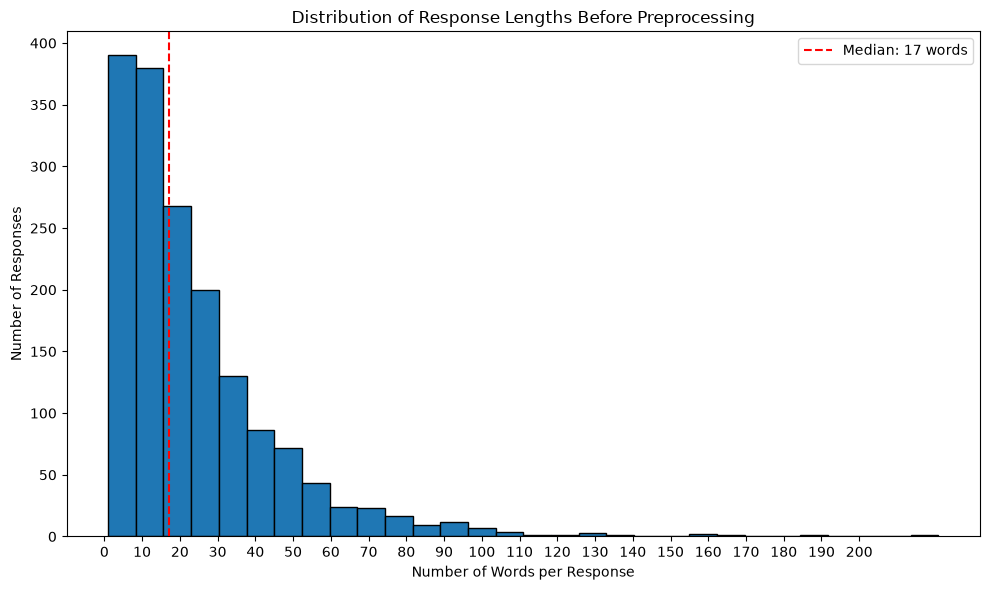

In [10]:
# Examining content in the text column
# Calculate response length before preprocessing
clean_df["word_count_before"]= clean_df["FacultySupportResponse"].str.split().str.len()


# Summary statistics
display(clean_df["word_count_before"].describe())

# Plot response-length distribution
plt.figure(figsize=(10, 6))

plt.hist(
    clean_df["word_count_before"],
    bins=30,
    edgecolor="black"
)

plt.axvline(
    clean_df["word_count_before"].median(),
    color="red",
    linestyle="--",
    label=f'Median: {clean_df["word_count_before"].median():.0f} words'
)
plt.xticks(range(0, 201, 10))
plt.title("Distribution of Response Lengths Before Preprocessing")
plt.xlabel("Number of Words per Response")
plt.ylabel("Number of Responses")
plt.legend()
plt.tight_layout()
# save_fig("05_response_length_before") #save graph
plt.show()


The Faculty Support dataset contains 1,676 valid responses, with an average length of approximately 24 words and a median of 17 words. Response lengths vary considerably, ranging from 1 to 221 words. The difference between the mean and median suggests a right-skewed distribution, with most responses being relatively short and a smaller number containing substantially more detail.

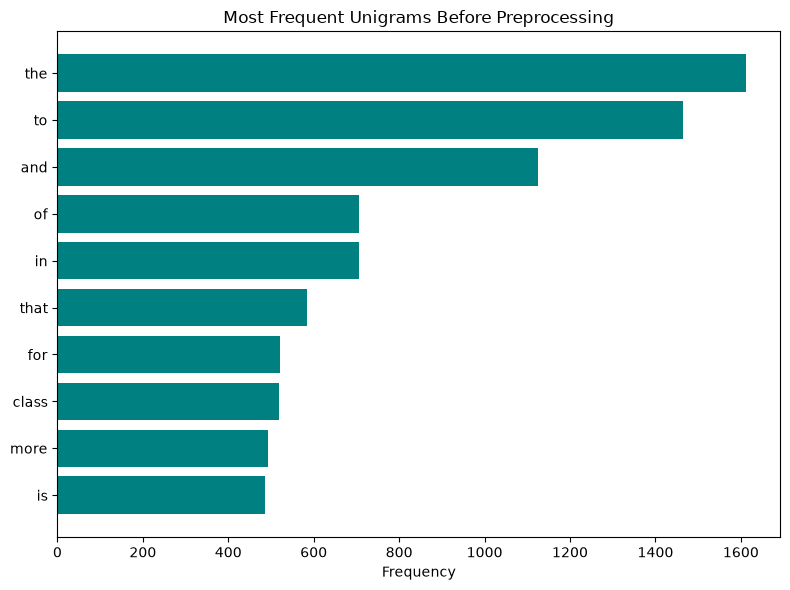

In [11]:
vec = CountVectorizer(ngram_range=(1, 1))
matrix = vec.fit_transform(clean_df[chosen_column])

uni_df = pd.DataFrame({
    "N-gram": vec.get_feature_names_out(),
    "Frequency": matrix.sum(axis=0).A1
}).nlargest(10, "Frequency")

plt.figure(figsize=(8, 6))
plt.barh(uni_df["N-gram"], uni_df["Frequency"], color="teal")
plt.gca().invert_yaxis()
plt.title("Most Frequent Unigrams Before Preprocessing")
plt.xlabel("Frequency")
plt.tight_layout()
# save_fig("07_ngrams_before_unigrams")
plt.show()

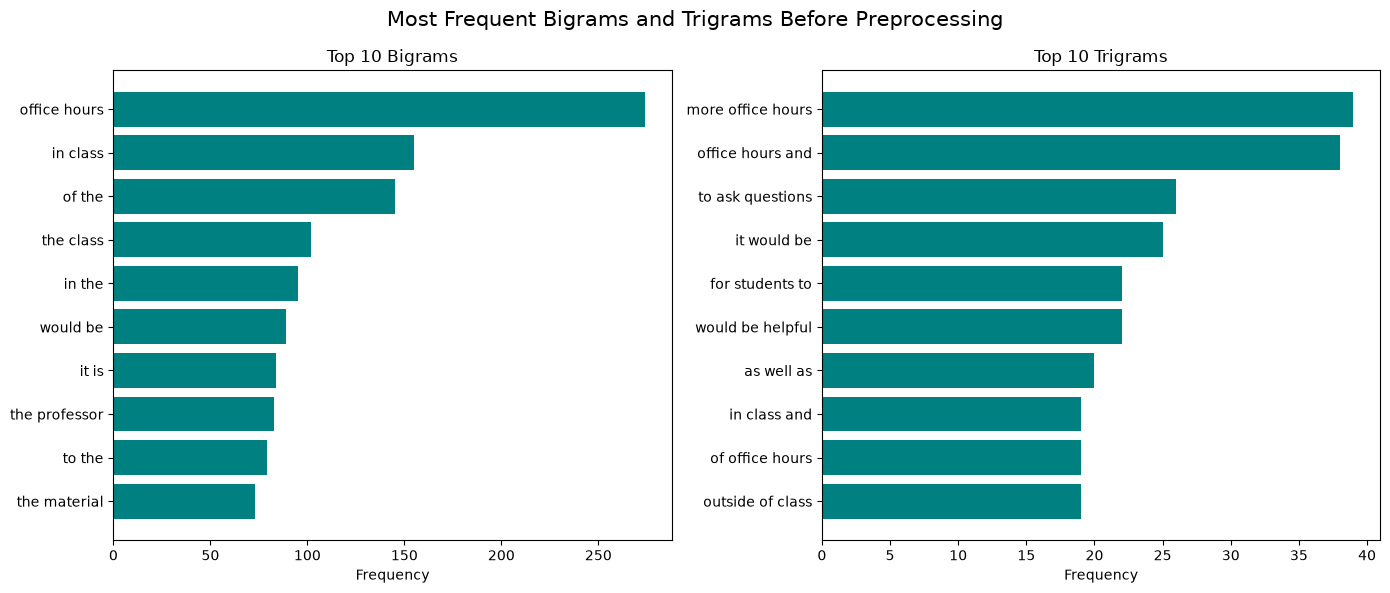

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, n, title in zip(axes, [2, 3], ["Top 10 Bigrams", "Top 10 Trigrams"]):
    vec = CountVectorizer(ngram_range=(n, n))
    matrix = vec.fit_transform(clean_df[chosen_column])

    ngram_df = pd.DataFrame({
        "N-gram": vec.get_feature_names_out(),
        "Frequency": matrix.sum(axis=0).A1
    }).nlargest(10, "Frequency")

    ax.barh(ngram_df["N-gram"], ngram_df["Frequency"], color="teal")
    ax.invert_yaxis()
    ax.set_title(title)
    ax.set_xlabel("Frequency")

plt.suptitle("Most Frequent Bigrams and Trigrams Before Preprocessing", fontsize=15)
plt.tight_layout()
# save_fig("07_ngrams_before_bigrams_trigrams")
plt.show()

This check shows the need for removing stopwords. Before our text preprocessing, the most common words are mostly just stop words

## 3. DATA PREPARATION

### 3.1 Text Preprocessing

In [13]:
#Define and apply function for text preprocessing
#instantiating stopword and lemmatizer
stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

#defining function for preprocessing that can be used for LDA, NMF and KMeans
def clean_text(text):
    text = str(text).lower()                            # 1. lowercase so "Notes" and "notes" count as the same word
    text = re.sub(r"[^a-z\s]", " ", text)               # 2. remove punctuation and numbers
    text = re.sub(r"https?://\S+", " ", text)           # 3. remove weblinks               
    words = word_tokenize(text)                         # 3. tokenize
    words = [w for w in words if w not in stop_words]   # 4. remove stop words
    words = [lemmatizer.lemmatize(w) for w in words]    # 5. lemmatize eg helpful -> help, professors -> professor
    words = [w for w in words if len(w) > 2]            # 6. drop 1 to 2 letter leftovers
    return " ".join(words)


#defining function for preprocessing that will be used for BertTopic (here we are not removing stopwords, lowercasing or removing punctuation)
def clean_for_bertopic(text):
    text = str(text)
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)   # remove weblinks
    text = re.sub(r"\s+", " ", text).strip()              # collapse extra spaces and line breaks
    return text



In [14]:
#applying text preprocessing to our chosen column and storing the cleaned text in a new column
clean_df["clean_text"] = clean_df[RESPONSE_COLUMN].apply(clean_text)

clean_df["bert_text"] = clean_df[RESPONSE_COLUMN].apply(clean_for_bertopic)

clean_df.head(1)

,Subject Code,FacultySupportResponse,word_count_before,clean_text,bert_text
0,1,"Better handwriting, hard to follow lecture sli...",9,better handwriting hard follow lecture slide time,"Better handwriting, hard to follow lecture sli..."


Note that the bert_text largely remains unchanged while their is a clear difference in the new clean_text column (lowercase, no punctuations). In the next steps, we will examine the clean_text column.

### 3.2 Examination of preprocessed responses

count    1676.000000
mean       12.639618
std        10.807635
min         1.000000
25%         6.000000
50%        10.000000
75%        16.000000
max       108.000000
Name: word_count, dtype: float64

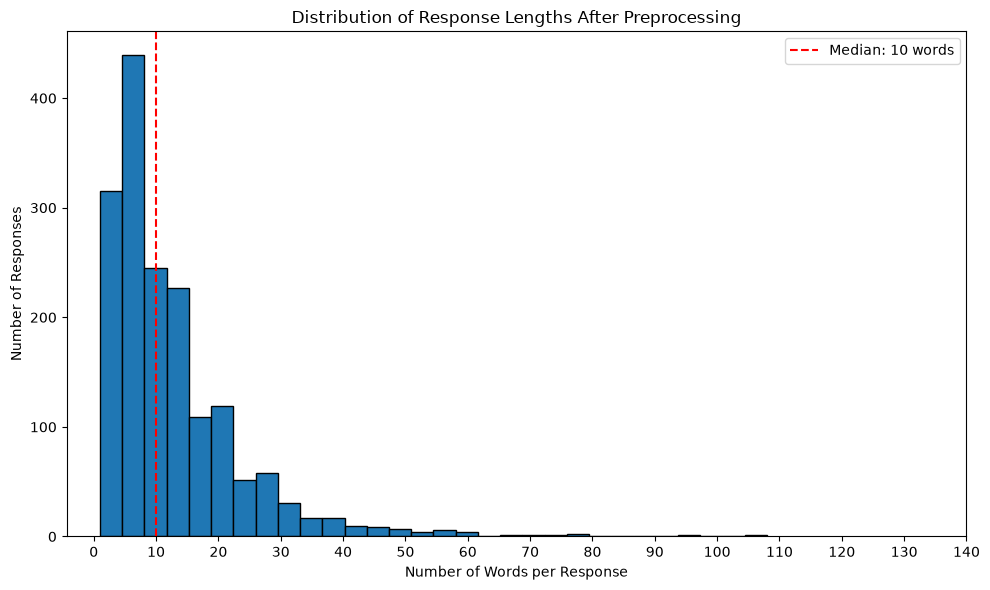

In [15]:

# Calculate response length after preprocessing
clean_df["word_count"] = clean_df["clean_text"].str.split().str.len()

# Summary statistics
display(clean_df["word_count"].describe())

# Plot response-length distribution
plt.figure(figsize=(10, 6))

plt.hist(
    clean_df["word_count"],
    bins=30,
    edgecolor="black"
)

plt.axvline(
    clean_df["word_count"].median(),
    color="red",
    linestyle="--",
    label=f'Median: {clean_df["word_count"].median():.0f} words'
)
plt.xticks(range(0, 150, 10))
plt.title("Distribution of Response Lengths After Preprocessing")
plt.xlabel("Number of Words per Response")
plt.ylabel("Number of Responses")
plt.legend()
plt.tight_layout()
# save_fig("08_response_length_after") #save graph
plt.show()


Following preprocessing, the average response length decreased from 23.6 to 12.6 words, while the median decreased from 17 to 10 words. This reduction reflects the removal of stopwords and other text elements during cleaning. The relatively short length of the processed responses is an important consideration for topic modelling, particularly for approaches that rely on word frequencies and co-occurrence patterns.

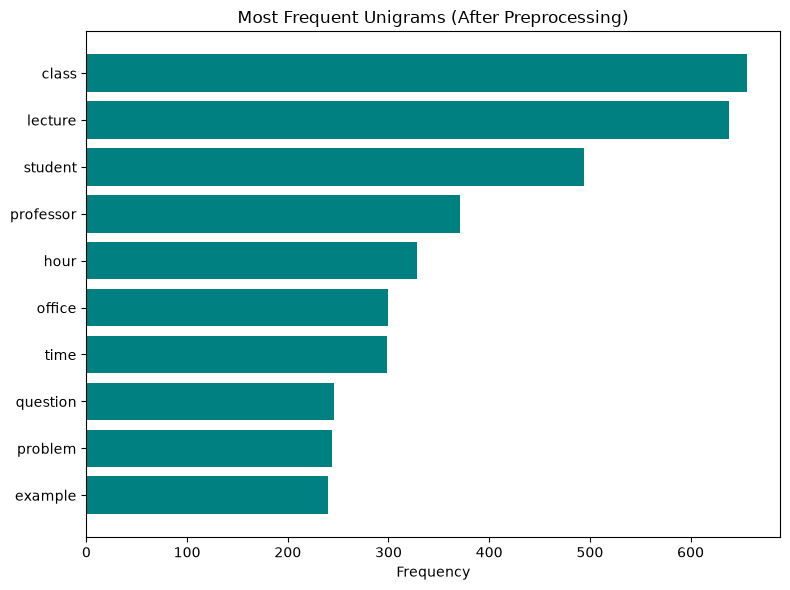

In [16]:
vec = CountVectorizer(ngram_range=(1, 1))
matrix = vec.fit_transform(clean_df["clean_text"])

uni_df = pd.DataFrame({
    "N-gram": vec.get_feature_names_out(),
    "Frequency": matrix.sum(axis=0).A1
}).nlargest(10, "Frequency")

plt.figure(figsize=(8, 6))
plt.barh(uni_df["N-gram"], uni_df["Frequency"], color="teal")
plt.gca().invert_yaxis()
plt.title("Most Frequent Unigrams (After Preprocessing)")
plt.xlabel("Frequency")
plt.tight_layout()
# save_fig("09_ngrams_after_unigrams")
plt.show()


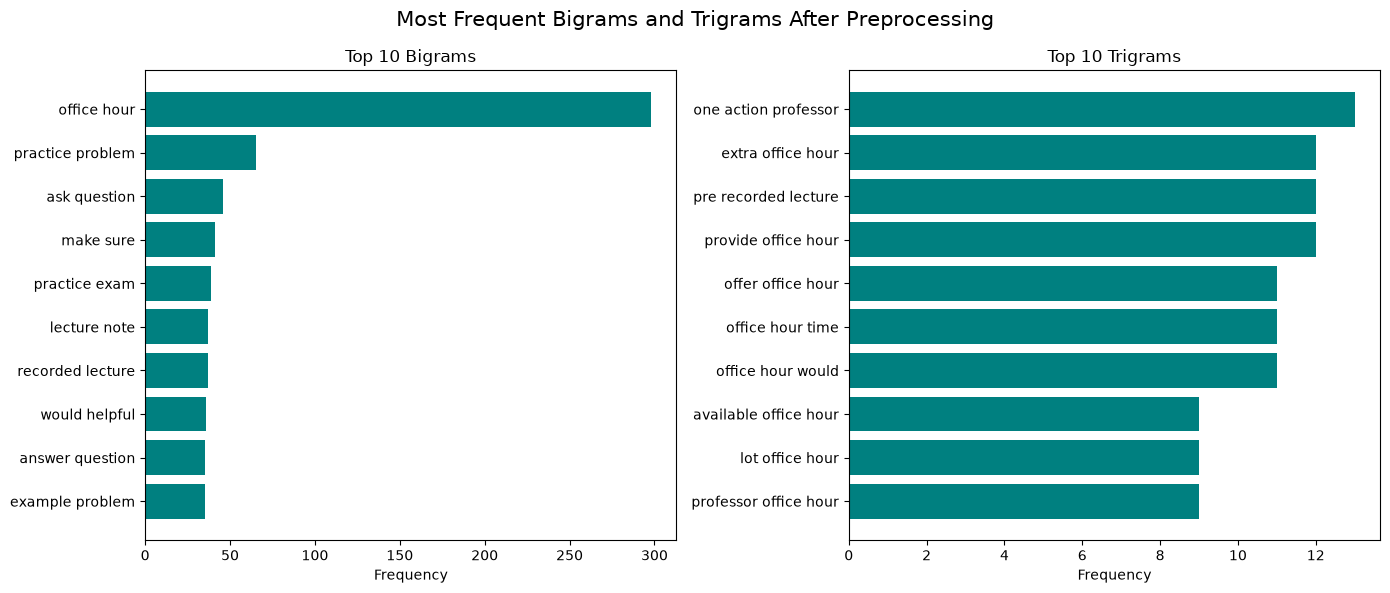

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, n, title in zip(axes, [2, 3], ["Top 10 Bigrams", "Top 10 Trigrams"]):
    vec = CountVectorizer(ngram_range=(n, n))
    matrix = vec.fit_transform(clean_df["clean_text"])

    ngram_df = pd.DataFrame({
        "N-gram": vec.get_feature_names_out(),
        "Frequency": matrix.sum(axis=0).A1
    }).nlargest(10, "Frequency")

    ax.barh(ngram_df["N-gram"], ngram_df["Frequency"], color="teal")
    ax.invert_yaxis()
    ax.set_title(title)
    ax.set_xlabel("Frequency")

plt.suptitle("Most Frequent Bigrams and Trigrams After Preprocessing", fontsize=15)
plt.tight_layout()
# save_fig("09_ngrams_after_bigrams_trigrams")
plt.show()

The n-gram analysis highlights frequently occurring words and phrases in the cleaned responses. While unigrams identify the most common individual terms, bigrams and trigrams provide additional context by showing words that frequently appear together. These patterns offer an initial indication of recurring concerns in the responses, although further topic modelling is required to identify broader themes.

,Word,Document Frequency,Percentage
0,lecture,490,29.236277
1,class,473,28.221957
2,student,357,21.300716
3,professor,302,18.019093
4,hour,277,16.527446
5,office,261,15.572792
6,time,235,14.021480
7,example,211,12.589499
8,problem,209,12.470167
9,question,208,12.410501


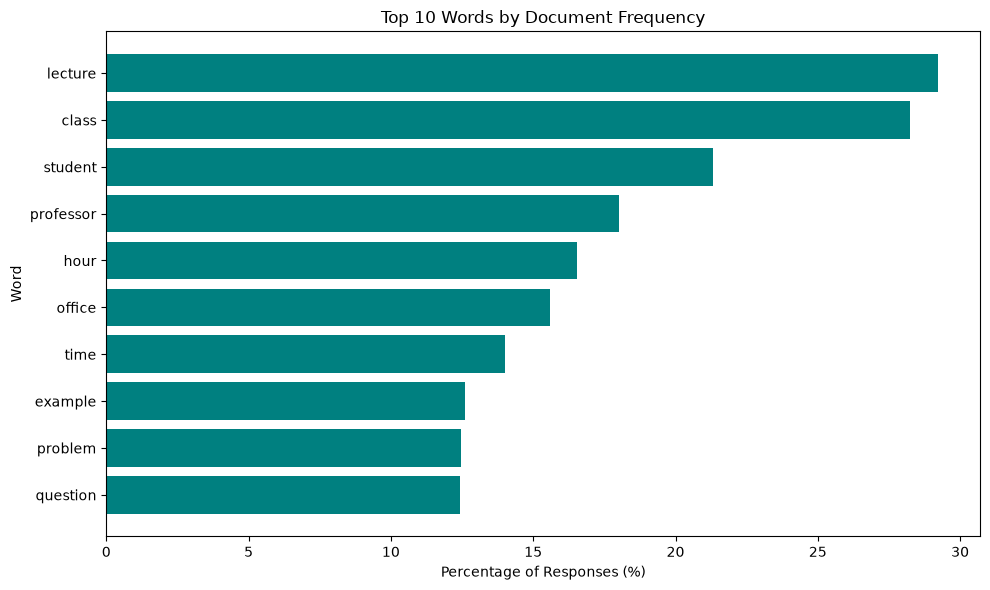

In [18]:

# Calculate document frequency
n_docs = len(clean_df)

doc_freq = Counter(
    word
    for text in clean_df["clean_text"]
    for word in set(text.split())
)

# Top 10 words and their percentages
top_doc_freq = pd.DataFrame(
    doc_freq.most_common(10),
    columns=["Word", "Document Frequency"]
)

top_doc_freq["Percentage"] = (
    top_doc_freq["Document Frequency"] / n_docs * 100
)
display(top_doc_freq)

# Visualize
plt.figure(figsize=(10, 6))

plt.barh(
    top_doc_freq["Word"],
    top_doc_freq["Percentage"],
    color="teal"
)

plt.gca().invert_yaxis()

plt.title("Top 10 Words by Document Frequency")
plt.xlabel("Percentage of Responses (%)")
plt.ylabel("Word")
plt.tight_layout()
# save_fig("10_document_frequency_top10") #save graph
plt.show()


Unlike word frequency, which counts the total number of times a word appears across all responses, **document frequency measures how many individual responses contain a particular word**, regardless of how often it appears within each response. This helps identify terms that are widely discussed across respondents rather than those repeated frequently by a smaller number of respondents.

The analysis shows that *lecture* and *class* appear in the largest proportion of responses, at 29.2% and 28.2%, respectively. Other prominent terms include *student*, *professor*, *hour*, and *office*, suggesting that classroom experiences, teaching practices, and instructor availability are common areas of discussion. However, these frequencies do not reveal the specific concerns expressed or the context in which these terms are used, highlighting the need for further topic modelling.

### 3.3 Removal of short responses

In [19]:

def examine_short_responses(df, text_col="clean_text", min_words=3):
    df = df.copy()

    # Calculate word count
    df["word_count"] = df[text_col].fillna("").str.split().str.len()

    # Identify short responses
    short_responses = df[df["word_count"] < min_words]

    print(f"Total responses: {len(df)}")
    print(f"Responses with fewer than {min_words} words: {len(short_responses)}")
    print(f"Percentage affected: {len(short_responses) / len(df):.1%}")

    # Display short responses, shortest first
    display(short_responses.sort_values("word_count"))

    return short_responses

short_responses = examine_short_responses(
    clean_df,
    min_words=MIN_WORDS
)

Total responses: 1676
Responses with fewer than 3 words: 73
Percentage affected: 4.4%


,Subject Code,FacultySupportResponse,word_count_before,clean_text,bert_text,word_count
640,652,Been flexible,2,flexible,Been flexible,1
572,584,Be flexible,2,flexible,Be flexible,1
1345,1370,Quizzes,1,quiz,Quizzes,1
1553,1581,Discussion,1,discussion,Discussion,1
330,337,more examples,2,example,more examples,1
...,...,...,...,...,...,...
415,423,Clear lectures,2,clear lecture,Clear lectures,2
410,418,Uploading notes,2,uploading note,Uploading notes,2
385,393,Be clear and organized.,4,clear organized,Be clear and organized.,2
490,499,Panopto Recordings,2,panopto recording,Panopto Recordings,2


### 3.4 Final Dataset for Modelling

In [20]:
# Set aside responses with fewer than 3 words for our models
short_df = short_responses.copy()
model_df = clean_df.drop(index=short_df.index).copy()

print(f"Responses retained for modelling: {len(model_df)}")
print(f"Short responses set aside: {len(short_df)}")
model_df.shape

Responses retained for modelling: 1603
Short responses set aside: 73


(1603, 6)

An examination of response lengths identified 73 responses (4.4%) containing fewer than three words after preprocessing. These responses were set aside because their limited word content may affect the ability of frequency-based topic-modelling approaches to identify meaningful patterns.

To ensure consistency in model evaluation, the remaining 1,603 responses will form the common dataset for comparing the different modelling approaches. LDA, NMF, and TF-IDF + KMeans will use the preprocessed `clean_text`, while BERTopic will use the corresponding `bert_text`, which retains more of the original sentence structure for semantic analysis. Using the same responses across models will allow for a more consistent comparison of their performance.

### EDA Summary

The exploratory analysis extracted a cleaned dataset of 1,676 Faculty Support responses and examined their length, vocabulary and frequently occurring terms. Preprocessing reduced the amount of text while retaining words relevant to the analysis. The findings also highlighted the relatively short nature of many survey responses, which will be considered during model development and evaluation.


The final dataset contains 1,603 responses after removing missing and very short responses.

Two text representations are retained for modelling: `clean_text`, which has undergone more extensive preprocessing for traditional topic modelling approaches, and `bert_text`, which preserves more of the original sentence structure for BERTopic.

The same set of responses is used across the models to ensure a consistent basis for comparison.


The next stage involves applying and comparing different topic-modelling approaches to identify recurring themes in the responses. The preprocessing and analysis procedures developed for the Faculty Support question will subsequently be adapted for the remaining two open-ended survey questions.




## 4. Topic Modelling and Evaluation

### Model Development

Four unsupervised topic modelling approaches are developed and compared:

1. Latent Dirichlet Allocation (LDA)
2. Non-Negative Matrix Factorization (NMF)
3. TF-IDF with KMeans Clustering
4. BERTopic

The models are evaluated using configurations of 3, 6, and 12 topics to examine how their performance changes with the number of topics identified.

### Model Evaluation

Model performance is assessed using three metrics:

- **C_v Coherence:** Measures the semantic relatedness of words within topics.
- **U_mass Coherence:** Measures word co-occurrence within the documents.
- **Cosine Similarity:** Measures the semantic similarity of responses assigned to the same topic.

These metrics are used together because each captures a different aspect of topic quality.


In [21]:
# VERIFY PREPROCESSED DATA
# Confirm that preprocessing produced the required datasets
required_columns = ["clean_text", "bert_text"]

for column in required_columns:
    if column not in model_df.columns:
        raise ValueError(f"Missing required column: {column}")

print("Preprocessed data ready for modelling.")
print(f"Selected response column: {RESPONSE_COLUMN}")
print(f"Responses available for modelling: {len(model_df):,}")

model_df[[RESPONSE_COLUMN, "clean_text", "bert_text"]].head()


Preprocessed data ready for modelling.
Selected response column: FacultySupportResponse
Responses available for modelling: 1,603


,FacultySupportResponse,clean_text,bert_text
0,"Better handwriting, hard to follow lecture sli...",better handwriting hard follow lecture slide time,"Better handwriting, hard to follow lecture sli..."
1,Variety of office hours so that all can get he...,variety office hour get help needed,Variety of office hours so that all can get he...
2,"Better lecture, no more ""is that good?""",better lecture good,"Better lecture, no more ""is that good?"""
3,Online resources; post more notes on line,online resource post note line,Online resources; post more notes on line
4,It would be better if we can have an equation ...,would better equation sheet,It would be better if we can have an equation ...


### 4.1 Model Development

#### 4.1.1 Vectorization

In [22]:
#Create count and TF-IDF document-term matrices.

MIN_DF = 2 #min_df means, ignore any word that appears in fewer than 2 answers 
MAX_DF = 0.95 #max_df ignores any words that appears in more than 90% of the answers


#FOR USE IN LDA
count_vectorizer = CountVectorizer(ngram_range=(1, 2),min_df=MIN_DF, max_df=MAX_DF)

#FOR USE IN NMF AND KMEANS
tfidf_vectorizer = TfidfVectorizer( ngram_range=(1, 2),min_df=MIN_DF, max_df=MAX_DF)

try:

    count_matrix = count_vectorizer.fit_transform(model_df["clean_text"])

    tfidf_matrix = tfidf_vectorizer.fit_transform(model_df["clean_text"])

except ValueError as exc:

    raise ValueError(
        "The vocabulary is empty. Try MIN_DF=1, "
        "relax MAX_DF, or inspect cleaned text."
    ) from exc


count_terms = count_vectorizer.get_feature_names_out()

tfidf_terms = tfidf_vectorizer.get_feature_names_out()

print("Count matrix:", count_matrix.shape)

print("TF-IDF matrix:", tfidf_matrix.shape)

Count matrix: (1603, 3356)
TF-IDF matrix: (1603, 3356)


#### 4.1.2 Defining configurations to be used for modelling and evaluation

In [23]:
RANDOM_STATE = 42
TOPIC_COUNTS = [3, 6, 12] # how many themes/topics we ask the model to find

# Text for BERTopic: the original wording (no stop word removal, no lemmatizing)
docs = model_df["bert_text"].astype(str).tolist()

#turn each answer into 384 numbers that capture its meaning
embedding_model = SentenceTransformer("all-MiniLM-L6-v2")
embeddings = embedding_model.encode(docs, batch_size=64, show_progress_bar=True)

def assign_outliers(model, docs, topics, embeddings, threshold=0.0):
    """Move every outlier (-1) to its closest topic, then refresh the keywords."""
    topics = np.array(topics).tolist()
    n_before = int(np.sum(np.array(topics) == -1))

    model = copy.deepcopy(model)          # keeps your original model untouched

    new_topics = model.reduce_outliers(
        docs, topics,
        strategy="embeddings",
        embeddings=embeddings,
        threshold=threshold
    )

    # refresh keywords using the same settings as the original model
    model.update_topics(
        docs,
        topics=new_topics,
        vectorizer_model=CountVectorizer(stop_words="english", ngram_range=(1, 2), min_df=1),
        top_n_words=10
    )

    new_topics = np.array(new_topics)
    n_after = int(np.sum(new_topics == -1))
    return model, new_topics, n_before, n_after

Batches:   0%|          | 0/26 [00:00<?, ?it/s]

In [24]:

# We are cleaning bert_text to ensure no words are excluded from the dictionary eg the word professors is in bert_text but not in clean_text
stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"[^a-z\s]", " ", text)
    text = re.sub(r"https?://\S+", " ", text)
    words = word_tokenize(text)
    words = [w for w in words if w not in stop_words]
    words = [lemmatizer.lemmatize(w) for w in words]
    words = [w for w in words if len(w) > 2]
    return " ".join(words)

TOP_N = 10

# create shared evaluation corpus (unigrams + bigrams from clean_text) 
analyzer = CountVectorizer(lowercase=False, ngram_range=(1, 2), min_df=1).build_analyzer()
tokenized_texts = [analyzer(t) for t in model_df["clean_text"].fillna("").astype(str)]
dictionary = Dictionary(tokenized_texts)
corpus = [dictionary.doc2bow(t) for t in tokenized_texts]

# keyword extraction (here we are extracting the top 10 words)
def extract_words(components, feature_names, top_n=TOP_N):
    return [[feature_names[i] for i in topic.argsort()[-top_n:][::-1]] for topic in components]

def get_bert_keywords(model, top_n=TOP_N):
    return [
        [word for word, _ in model.get_topic(tid)[:top_n]]
        for tid in sorted(model.get_topics())
        if tid != -1
    ]

# clean BERTopic keywords like clean_text, keep only shared-vocabulary words 
def prepare_topics(raw_topics, from_bert=False):
    cleaned = []
    for topic in raw_topics:
        words = [clean_text(w) for w in topic] if from_bert else list(topic)
        cleaned.append(list(dict.fromkeys(w for w in words if w)))   # drop empties and duplicates

    kept = [[w for w in t if w in dictionary.token2id] for t in cleaned]
    total = sum(len(t) for t in cleaned)
    retained = sum(len(t) for t in kept)
    return kept, (retained / total * 100 if total else np.nan)


### 4.2 Defining Evaluation Metrics

In [25]:
def cv_coherence(topics):
    usable = [t for t in topics if len(t) >= 2]      # coherence needs at least 2 words
    if not usable:
        return np.nan
    cm = CoherenceModel(
        topics=usable,
        texts=tokenized_texts,
        dictionary=dictionary,
        coherence="c_v",
        processes=1                                   # avoids multiprocessing hangs on Windows
    )
    return cm.get_coherence()

def umass_coherence(topics):
    usable = [t for t in topics if len(t) >= 2]
    if not usable:
        return np.nan
    cm = CoherenceModel(
        topics=usable,
        corpus=corpus,
        dictionary=dictionary,
        coherence="u_mass",
        processes=1
    )
    return cm.get_coherence()

# MEAN INTRA-TOPIC COSINE SIMILARITY (ALL MODELS)
def topic_cosine_similarity(labels):
    labels = np.asarray(labels)
    similarities = []

    for topic in sorted(set(labels) - {-1}):
        members = embeddings[labels == topic]

        if len(members) < 2:
            continue

        centre = members.mean(axis=0, keepdims=True)
        values = cosine_similarity(members, centre).ravel()
        similarities.extend(values.tolist())

    return float(np.mean(similarities)) if similarities else np.nan

### 4.3 Modelling and Evaluation

In [26]:
#To avoid repeating the same code for the 3 different topics, we will run a for loop for both modelling and evaluation
all_results = []

for n_topics in TOPIC_COUNTS:

    print(f"\n{'='*55}")
    print(f"EVALUATING {n_topics} TOPICS")
    print(f"{'='*55}")

    # ---------------- LDA ----------------
    lda = LatentDirichletAllocation(
        n_components=n_topics,
        random_state=RANDOM_STATE
    )
    lda_topics = lda.fit_transform(count_matrix)

    # ---------------- NMF ----------------
    nmf = NMF(
        n_components=n_topics,
        init="nndsvd",
        random_state=RANDOM_STATE
    )
    nmf_topics = nmf.fit_transform(tfidf_matrix)

    # ---------------- KMEANS ----------------
    kmeans = KMeans(
        n_clusters=n_topics,
        random_state=RANDOM_STATE,
        n_init=10
    )
    kmeans_topics = kmeans.fit_predict(tfidf_matrix)

    # ---------------- BERTOPIC ----------------
    umap_model = UMAP(
        n_neighbors=15,
        n_components=5,
        min_dist=0.0,
        metric="cosine",
        random_state=RANDOM_STATE
    )

    hdbscan_model = HDBSCAN(
        min_cluster_size=15,
        min_samples=5,
        metric="euclidean",
        cluster_selection_method="eom",
        prediction_data=True
    )

    bert_vectorizer = CountVectorizer(
        stop_words="english",
        ngram_range=(1, 2),
        min_df=1
    )

    bert_model = BERTopic(
        embedding_model=embedding_model,
        umap_model=umap_model,
        hdbscan_model=hdbscan_model,
        vectorizer_model=bert_vectorizer,
        nr_topics=n_topics + 1,
        top_n_words=10,
        verbose=False
    )

    bert_topics, bert_probs = bert_model.fit_transform(
        docs, embeddings
    )

    bert_topics = np.array(bert_topics)

    # Your existing outlier reassignment function
    bert_final, bert_topics_final, n_before, n_after = (
        assign_outliers(
            bert_model, docs, bert_topics, embeddings
        )
    )

    print(f"BERTopic outliers: {n_before} -> {n_after}")

    # ---------------- KEYWORD EXTRACTION ----------------
    # Your original extraction and preparation functions

    raw_topic_keywords = {
        "LDA": extract_words(lda.components_, count_terms),
        "NMF": extract_words(nmf.components_, tfidf_terms),
        "KMeans": extract_words(
            kmeans.cluster_centers_, tfidf_terms
        ),
        "BERTopic": get_bert_keywords(bert_final)
    }

    eval_topics = {}

    for name, raw in raw_topic_keywords.items():
        eval_topics[name], retention = prepare_topics(
            raw,
            from_bert=(name == "BERTopic")
        )

        too_short = sum(
            len(t) < 2 for t in eval_topics[name]
        )

        print(
            f"{name:9s} topics: {len(eval_topics[name])} | "
            f"keywords retained: {retention:.1f}% | "
            f"topics with <2 keywords: {too_short}"
        )

    # ---------------- EVALUATION ----------------
    # Calling your existing functions unchanged

    cv_scores = {
        name: cv_coherence(topics)
        for name, topics in eval_topics.items()
    }

    umass_scores = {
        name: umass_coherence(topics)
        for name, topics in eval_topics.items()
    }

    topic_labels = {
        "LDA": lda_topics.argmax(axis=1),
        "NMF": nmf_topics.argmax(axis=1),
        "KMeans": kmeans_topics,
        "BERTopic": bert_topics_final
    }

    cosine_scores = {
        name: topic_cosine_similarity(labels)
        for name, labels in topic_labels.items()
    }

    # ---------------- STORE RESULTS ----------------

    for name in eval_topics:
        all_results.append({
            "Requested Topics": n_topics,
            "Model": name,
            "Actual Topics": len(eval_topics[name]),
            "C_v Coherence": cv_scores[name],
            "U_mass Coherence": umass_scores[name],
            "Cosine Similarity": cosine_scores[name]
        })

    print(f"\nCompleted evaluation for n = {n_topics}")

results_all = pd.DataFrame(all_results)
display(results_all)





EVALUATING 3 TOPICS


2026-11-17 22:43:42,146 - BERTopic - WARNING: Using a custom list of topic assignments may lead to errors if topic reduction techniques are used afterwards. Make sure that manually assigning topics is the last step in the pipeline.Note that topic embeddings will also be created through weightedc-TF-IDF embeddings instead of centroid embeddings.


BERTopic outliers: 499 -> 0
LDA       topics: 3 | keywords retained: 100.0% | topics with <2 keywords: 0
NMF       topics: 3 | keywords retained: 100.0% | topics with <2 keywords: 0
KMeans    topics: 3 | keywords retained: 100.0% | topics with <2 keywords: 0
BERTopic  topics: 3 | keywords retained: 100.0% | topics with <2 keywords: 0

Completed evaluation for n = 3

EVALUATING 6 TOPICS


2026-11-17 22:44:02,930 - BERTopic - WARNING: Using a custom list of topic assignments may lead to errors if topic reduction techniques are used afterwards. Make sure that manually assigning topics is the last step in the pipeline.Note that topic embeddings will also be created through weightedc-TF-IDF embeddings instead of centroid embeddings.


BERTopic outliers: 499 -> 0
LDA       topics: 6 | keywords retained: 100.0% | topics with <2 keywords: 0
NMF       topics: 6 | keywords retained: 100.0% | topics with <2 keywords: 0
KMeans    topics: 6 | keywords retained: 100.0% | topics with <2 keywords: 0
BERTopic  topics: 6 | keywords retained: 100.0% | topics with <2 keywords: 0

Completed evaluation for n = 6

EVALUATING 12 TOPICS


2026-11-17 22:44:19,095 - BERTopic - WARNING: Using a custom list of topic assignments may lead to errors if topic reduction techniques are used afterwards. Make sure that manually assigning topics is the last step in the pipeline.Note that topic embeddings will also be created through weightedc-TF-IDF embeddings instead of centroid embeddings.


BERTopic outliers: 499 -> 0
LDA       topics: 12 | keywords retained: 100.0% | topics with <2 keywords: 0
NMF       topics: 12 | keywords retained: 100.0% | topics with <2 keywords: 0
KMeans    topics: 12 | keywords retained: 100.0% | topics with <2 keywords: 0
BERTopic  topics: 12 | keywords retained: 100.0% | topics with <2 keywords: 0

Completed evaluation for n = 12


,Requested Topics,Model,Actual Topics,C_v Coherence,U_mass Coherence,Cosine Similarity
0,3,LDA,3,0.526076,-1.802672,0.580552
1,3,NMF,3,0.535672,-3.283081,0.598008
2,3,KMeans,3,0.542970,-2.429743,0.604124
3,3,BERTopic,3,0.540656,-1.915886,0.609974
4,6,LDA,6,0.501194,-2.009543,0.587774
5,6,NMF,6,0.569598,-3.787757,0.624803
6,6,KMeans,6,0.546674,-2.641243,0.621225
7,6,BERTopic,6,0.569347,-2.033522,0.628941
8,12,LDA,12,0.517346,-2.109325,0.594063
9,12,NMF,12,0.498558,-5.816611,0.637438


### 4.4 Comparison of Model Perfomance

In [27]:
palette = ["#4C72B0", "#55A868", "#C44E52", "#8172B2"]

def plot_metric_bars(df, metric_cols, title=None):
    fig, axes = plt.subplots(1, len(metric_cols), figsize=(5.3 * len(metric_cols), 5))
    for ax, col in zip(axes, metric_cols):
        values = df[col].values.astype(float)
        bars = ax.bar(df.index, values, color=palette[:len(df)])
        best = np.nanargmin(values) if "↓" in col else np.nanargmax(values)
        bars[best].set_edgecolor("black")
        bars[best].set_linewidth(2.5)
        ax.bar_label(bars, fmt="%.3f", padding=3)
        ax.set_title(col, fontsize=12)
        ax.margins(y=0.18)
        ax.tick_params(axis="x", rotation=0)
    if title:
        fig.suptitle(title, fontsize=14)
    plt.tight_layout()
    plt.show()



MODEL COMPARISON: 3 TOPICS


,Actual Topics,C_v Coherence,U_mass Coherence,Cosine Similarity
Model,,,,
LDA,3,0.526,-1.803,0.581
NMF,3,0.536,-3.283,0.598
KMeans,3,0.543,-2.430,0.604
BERTopic,3,0.541,-1.916,0.610


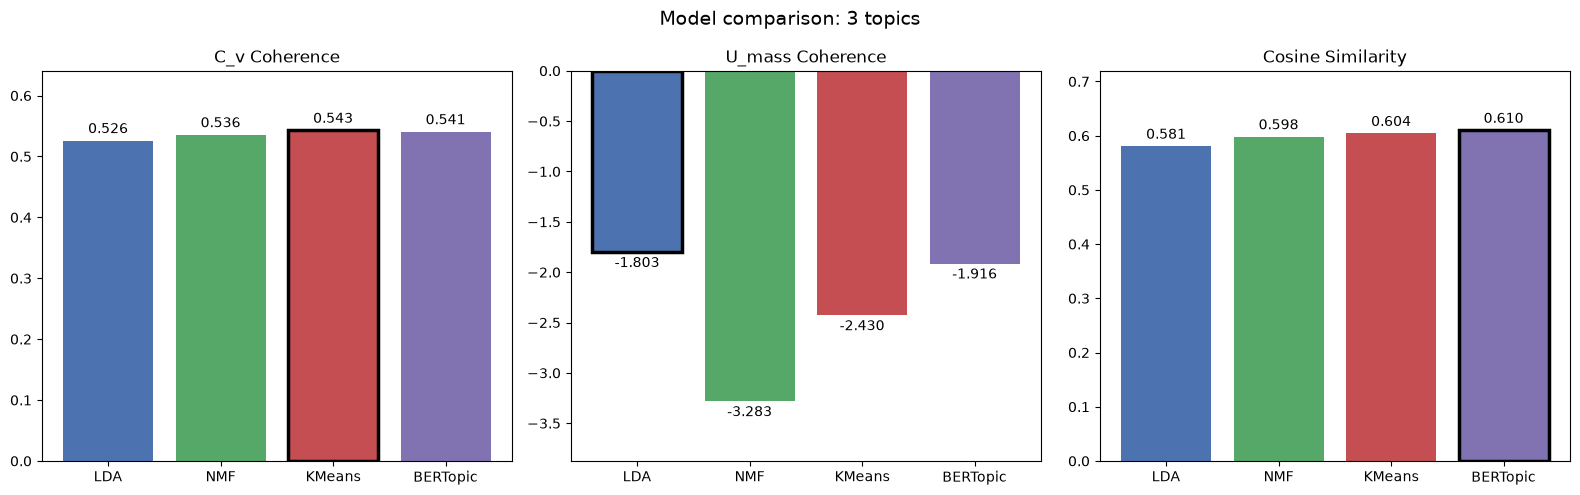


MODEL COMPARISON: 6 TOPICS


,Actual Topics,C_v Coherence,U_mass Coherence,Cosine Similarity
Model,,,,
LDA,6,0.501,-2.010,0.588
NMF,6,0.570,-3.788,0.625
KMeans,6,0.547,-2.641,0.621
BERTopic,6,0.569,-2.034,0.629


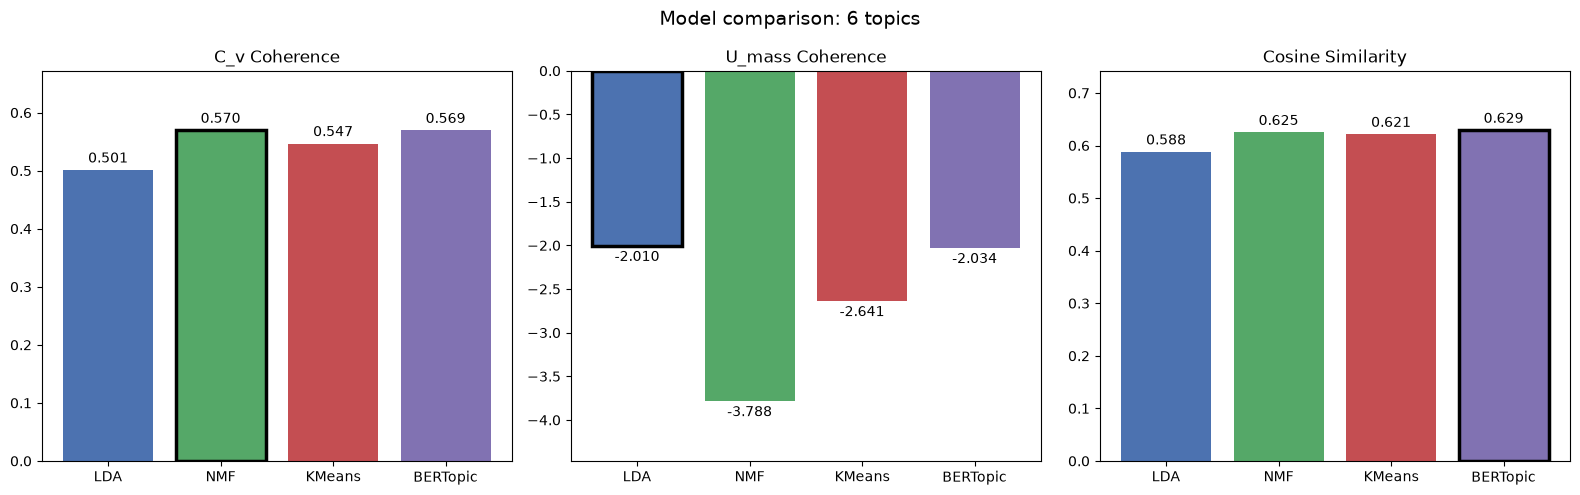


MODEL COMPARISON: 12 TOPICS


,Actual Topics,C_v Coherence,U_mass Coherence,Cosine Similarity
Model,,,,
LDA,12,0.517,-2.109,0.594
NMF,12,0.499,-5.817,0.637
KMeans,12,0.531,-3.115,0.639
BERTopic,12,0.532,-2.989,0.664


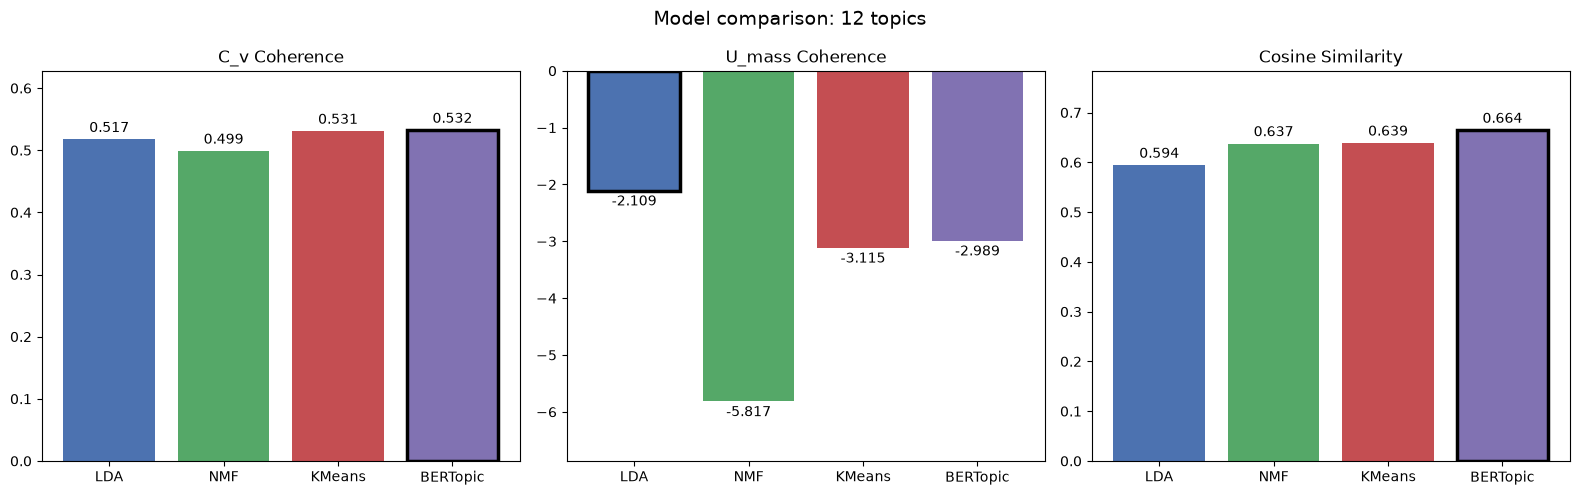

In [28]:

metric_cols = [
    "C_v Coherence",
    "U_mass Coherence",
    "Cosine Similarity"
]

for n_topics in TOPIC_COUNTS:

    df = (
        results_all[
            results_all["Requested Topics"] == n_topics
        ]
        .set_index("Model")
    )

    print(f"\nMODEL COMPARISON: {n_topics} TOPICS")

    display(
        df[["Actual Topics"] + metric_cols]
        .style
        .format("{:.3f}", subset=metric_cols)
        .highlight_max(
            subset=metric_cols,
            color="#c6efce"
        )
    )
    # save the table as a CSV
    df[["Actual Topics"] + metric_cols].round(3).to_csv(
        FIG_DIR / f"11_model_comparison2_{n_topics}_topics.csv")

    # Your existing plotting function
    plot_metric_bars(
        df,
        metric_cols,
        title=f"Model comparison: {n_topics} topics"
    )

Saved figure: 12_C_v Coherence_by_topic_count


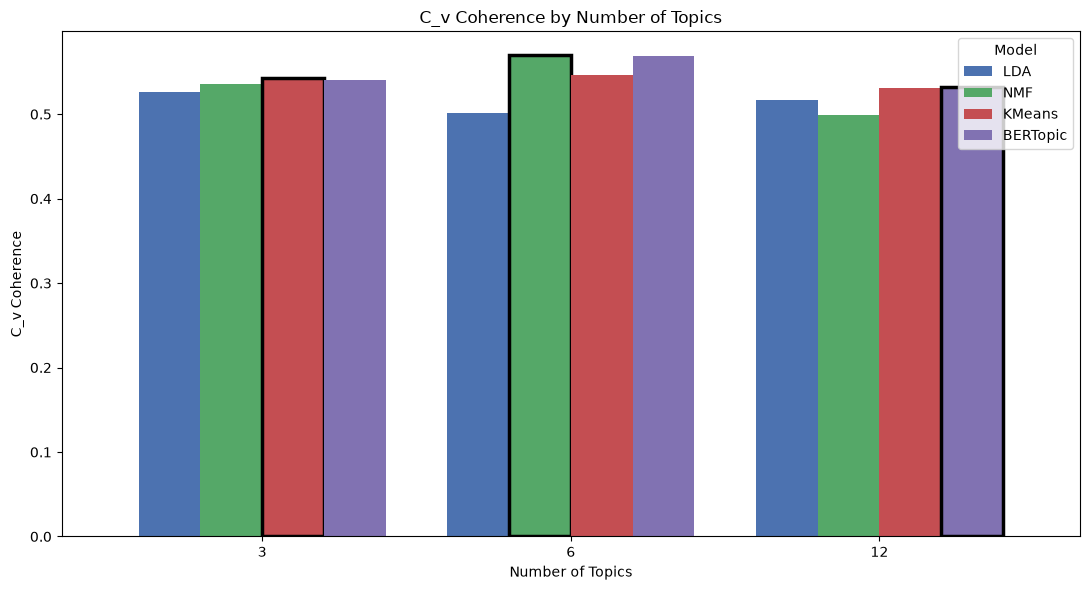

Saved figure: 12_U_mass Coherence_by_topic_count


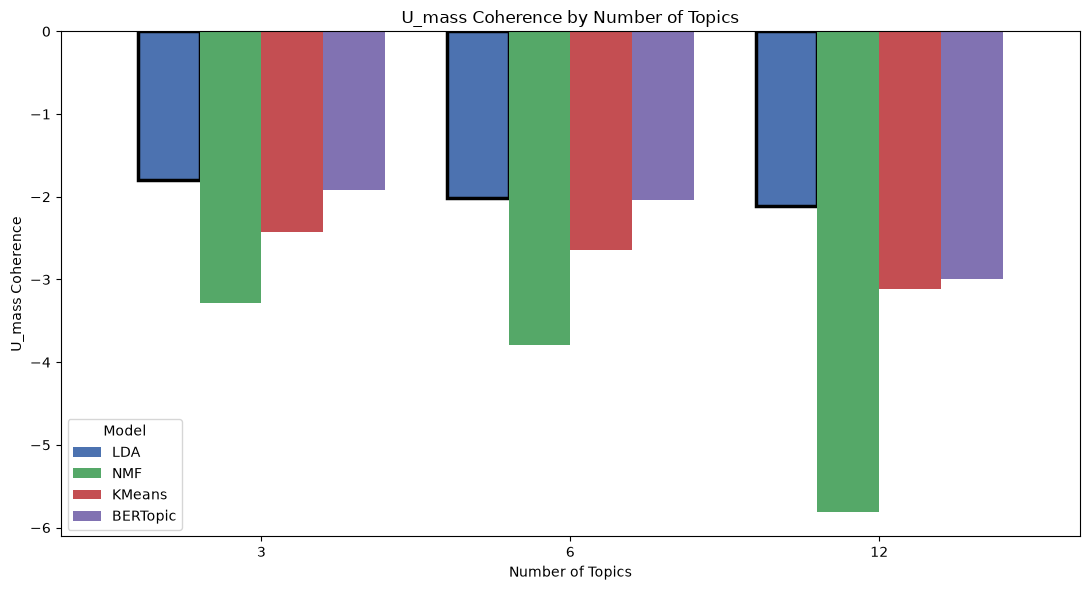

Saved figure: 12_Cosine Similarity_by_topic_count


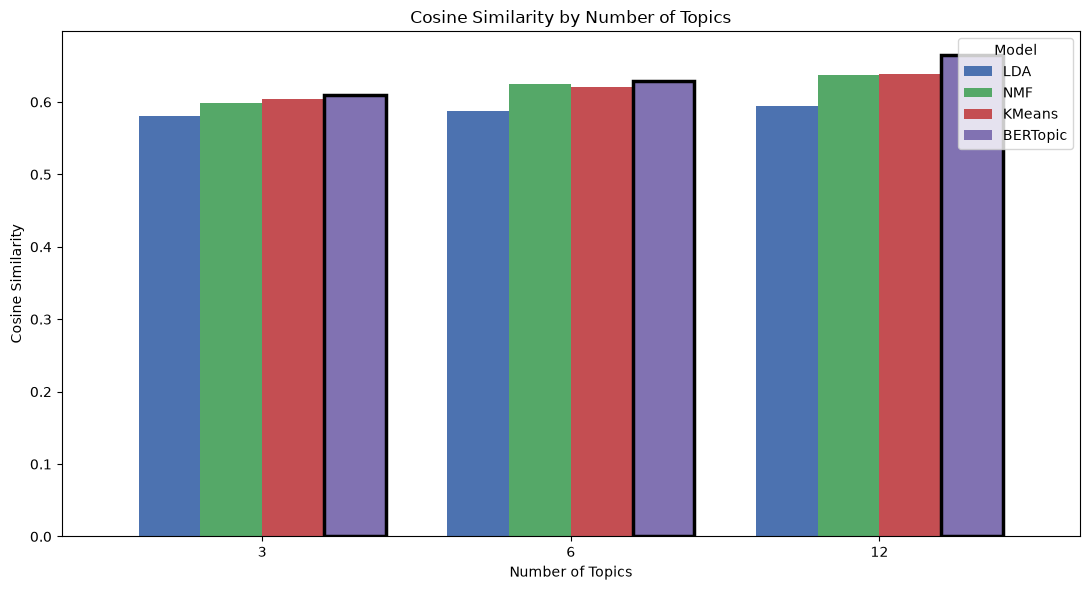

In [29]:
palette = ["#4C72B0", "#55A868", "#C44E52", "#8172B2"]

models = ["LDA", "NMF", "KMeans", "BERTopic"]

for metric in metric_cols:

    comparison = results_all.pivot(
        index="Requested Topics",
        columns="Model",
        values=metric
    )

    comparison = comparison[models]

    ax = comparison.plot(
        kind="bar",
        figsize=(11, 6),
        color=palette,
        width=0.8
    )

    ax.set_title(f"{metric} by Number of Topics")
    ax.set_xlabel("Number of Topics")
    ax.set_ylabel(metric)
    ax.set_xticklabels(
        comparison.index,
        rotation=0
    )
    ax.legend(title="Model")

    # Highlight the winning model at each topic count
    for i, n_topics in enumerate(comparison.index):

        values = comparison.loc[n_topics]
        winner = values.idxmax()
        winner_index = models.index(winner)

        # Matplotlib groups bars by model
        winning_bar = ax.containers[winner_index][i]
        winning_bar.set_edgecolor("black")
        winning_bar.set_linewidth(2.5)

    plt.tight_layout()
    # save the graph 
    save_fig(f"12_{metric}_by_topic_count")
    plt.show()


#### 4.4.1 C_v Coherence

C_v coherence measures the semantic relatedness of the words representing each topic. Higher scores generally indicate that the topic keywords are more closely associated and therefore potentially easier to interpret.

The C_v coherence results show considerable variation across the models and topic configurations. At 3 topics, KMeans achieved the highest coherence score of 0.543, closely followed by BERTopic at 0.541. At 6 topics, NMF achieved the highest score of 0.570, although BERTopic followed closely at 0.569. At 12 topics, BERTopic recorded the highest score of 0.532, marginally exceeding KMeans at 0.531.

BERTopic demonstrated relatively consistent performance, with scores ranging from 0.532 to 0.569. KMeans also showed limited variation, recording scores between 0.531 and 0.547. In contrast, NMF showed the greatest variation, suggesting that its coherence performance was more sensitive to the number of topics selected.


#### 4.4.2 U_mass Coherence

U_mass coherence measures how frequently the words within a topic appear together in the same documents. Scores are typically negative, with values closer to zero indicating stronger coherence.

Unlike C_v coherence, the U_mass results consistently favoured LDA across all three topic configurations with BERTopic consistently ranking second. NMF recorded the lowest U_mass coherence scores across all configurations. Its performance declined from -3.283 at 3 topics to -5.817 at 12 topics, representing the largest deterioration among the four models. KMeans also recorded progressively lower scores as the number of topics increased.

An important observation is that U_mass coherence declined for all four models as the number of topics increased. The strongest results were consistently obtained with 3 topics, suggesting that dividing the responses into more topics did not improve the co-occurrence relationships among the selected topic keywords.


#### 4.4.3 Cosine Similarity

This project defined cosine similarity as how closely related the responses assigned to the same topic are within a shared semantic embedding space. Higher scores indicate that responses grouped under the same topic are more semantically similar.

BERTopic achieved the highest cosine similarity scores across all three configurations, recording 0.610, 0.629, and 0.664 for 3, 6, and 12 topics, respectively. This indicates that, within the selected embedding space, the responses grouped by BERTopic were more semantically similar on average than those grouped by the other models.

KMeans and NMF also performed relatively well, particularly at 12 topics, where they achieved scores of 0.639 and 0.637, respectively. LDA consistently recorded the lowest cosine similarity scores, ranging from 0.581 to 0.594.

Unlike the coherence metrics, cosine similarity increased for all four models as the number of topics increased. This suggests that dividing responses into smaller groups resulted in greater within-topic semantic similarity.




### 4.5 Selection of Final Model
Based on the comparative evaluation, BERTopic was selected as the preferred modelling approach for the subsequent analysis of open-ended survey responses.
Although BERTopic did not achieve the highest scores across all evaluation metrics, it demonstrated strong and consistent performance. It achieved the highest cosine similarity scores across all three topic configurations. For C_v coherence, while the rankings of the other models varied across the different topic configurations, BERTopic consistently ranked among the top two performing models, achieving the highest score at 12 topics. Similarly, for U_mass coherence, BERTopic consistently ranked second after LDA across all three configurations. This consistency across the evaluation metrics, particularly when compared to the varying performance of the other models, provides a strong basis for its selection.


## 5. Sentiment Analysis Using RoBERTa

Sentiment analysis was conducted using the pretrained `cardiffnlp/twitter-roberta-base-sentiment-latest` model to classify responses as Positive, Neutral or Negative.

The analysis uses the same dataset retained for topic modelling (`model_df`), with the `bert_text` column preserving the original wording of responses. Responses excluded during data preparation were therefore not reintroduced.

In addition to the predicted sentiment, the model provides a confidence score representing the probability assigned to its selected class.

### 5.1 Defining RoBERTa model

In [30]:
# Model configuration
MODEL_NAME = "cardiffnlp/twitter-roberta-base-sentiment-latest"
BATCH_SIZE = 8
MAX_TOKENS = 512
CHUNK_STRIDE = 64
CONFIDENCE_THRESHOLD = 0.70

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# Load pretrained model and tokenizer
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, use_fast=True)
model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME)
model.to(device)
model.eval()

# Check sentiment labels
raw_labels = [
    str(model.config.id2label[i]).strip().lower()
    for i in range(model.config.num_labels)
]

label_lookup = {
    "negative": "Negative",
    "neutral": "Neutral",
    "positive": "Positive"
}

if all(label in label_lookup for label in raw_labels):
    labels = [label_lookup[label] for label in raw_labels]
elif raw_labels == ["label_0", "label_1", "label_2"]:
    labels = ["Negative", "Neutral", "Positive"]
else:
    raise ValueError(f"Unexpected model labels: {raw_labels}")


def predict_sentiment(texts):
    """Predict sentiment and confidence for each response."""

    texts = [str(text) for text in texts]

    # Tokenize responses, splitting long responses into overlapping chunks
    all_chunks = []
    chunk_owners = []

    for response_index, response in enumerate(texts):
        encoded = tokenizer(
            response,
            truncation=True,
            max_length=MAX_TOKENS,
            stride=CHUNK_STRIDE,
            return_overflowing_tokens=True,
            add_special_tokens=True
        )

        chunks = encoded["input_ids"]

        if chunks and isinstance(chunks[0], int):
            chunks = [chunks]

        for chunk in chunks:
            all_chunks.append(chunk)
            chunk_owners.append(response_index)

    probability_sums = np.zeros((len(texts), 3))
    chunk_counts = np.zeros(len(texts))

    # Run inference in batches
    for start in range(0, len(all_chunks), BATCH_SIZE):
        batch_ids = all_chunks[start:start + BATCH_SIZE]

        batch = tokenizer.pad(
            {"input_ids": batch_ids},
            padding=True,
            return_tensors="pt"
        ).to(device)

        with torch.inference_mode():
            logits = model(**batch).logits
            probabilities = torch.softmax(logits, dim=-1).cpu().numpy()

        for offset, scores in enumerate(probabilities):
            owner = chunk_owners[start + offset]
            probability_sums[owner] += scores
            chunk_counts[owner] += 1

    # Average probabilities across chunks
    probabilities = probability_sums / chunk_counts[:, None]

    predictions = probabilities.argmax(axis=1)
    confidence = probabilities.max(axis=1)

    return pd.DataFrame({
        "sentiment": [labels[i] for i in predictions],
        "confidence_score": np.round(confidence * 100, 1),
        "review_flag": np.where(
            confidence < CONFIDENCE_THRESHOLD,
            "Review",
            "Classified"
        )
    })


# Apply RoBERTa to the retained responses
sentiment_df = model_df.copy().reset_index(drop=True)

predictions = predict_sentiment(sentiment_df["bert_text"].tolist())

sentiment_df = pd.concat([sentiment_df, predictions], axis=1)

print(f"Responses classified: {len(sentiment_df):,}")
display(
    sentiment_df[
        [RESPONSE_COLUMN, "sentiment", "confidence_score", "review_flag"]
    ].head(10)
)

Using device: cpu


Some weights of the model checkpoint at cardiffnlp/twitter-roberta-base-sentiment-latest were not used when initializing RobertaForSequenceClassification: ['roberta.pooler.dense.bias', 'roberta.pooler.dense.weight']
- This IS expected if you are initializing RobertaForSequenceClassification from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing RobertaForSequenceClassification from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).
You're using a RobertaTokenizerFast tokenizer. Please note that with a fast tokenizer, using the `__call__` method is faster than using a method to encode the text followed by a call to the `pad` method to get a padded encoding.


Responses classified: 1,603


,FacultySupportResponse,sentiment,confidence_score,review_flag
0,"Better handwriting, hard to follow lecture sli...",Neutral,53.8,Review
1,Variety of office hours so that all can get he...,Neutral,78.7,Classified
2,"Better lecture, no more ""is that good?""",Positive,55.6,Review
3,Online resources; post more notes on line,Neutral,89.8,Classified
4,It would be better if we can have an equation ...,Neutral,66.1,Review
5,Be specific as to what will be asked for on th...,Neutral,85.4,Classified
6,Make class smaller,Neutral,62.4,Review
7,Make document summarizing all important equati...,Neutral,83.7,Classified
8,Email class notes after every class.,Neutral,85.1,Classified
9,Take the time to explain concepts more in dept...,Neutral,52.7,Review


In [31]:
# Export sentiment analysis results to Excel
excel_path = FIG_DIR.parent / "roberta_sentiment_results.xlsx"

sentiment_df.to_excel(
    excel_path,
    sheet_name="Sentiment Predictions",
    index=False
)

print(f"Excel file saved: {excel_path}")

Excel file saved: outputs\faculty_support\roberta_sentiment_results.xlsx


### 5.2 Distribution of Predicted Sentiments

The distribution of predicted sentiments was examined to establish the proportion of responses classified as Positive, Neutral and Negative.

It is important to note that the original survey question requested feedback and suggestions rather than explicitly asking respondents to express positive or negative sentiments. The results therefore represent sentiments inferred by the model, rather than direct sentiment ratings provided by respondents.

,Count,Percentage (%)
sentiment,,
Positive,353,22.0
Neutral,1127,70.3
Negative,123,7.7


Saved figure: roberta_sentiment_distribution_3


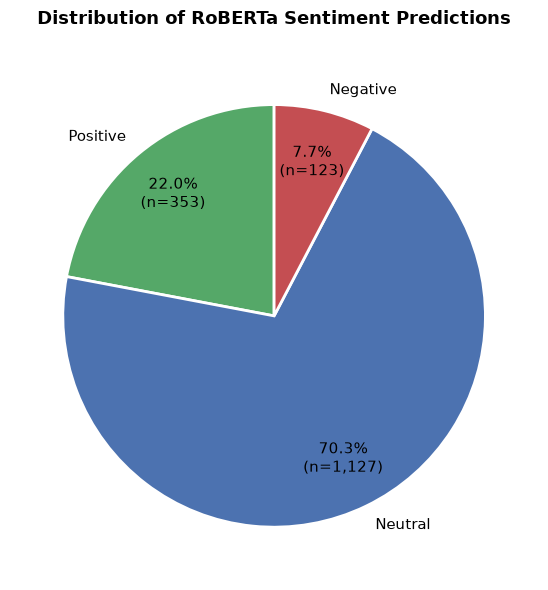

In [32]:
SENTIMENT_ORDER = ["Positive", "Neutral", "Negative"]

SENTIMENT_COLORS = {
    "Positive": "#55A868",
    "Neutral": "#4C72B0",
    "Negative": "#C44E52"
}


# Calculate sentiment distribution
sentiment_counts = (
    sentiment_df["sentiment"]
    .value_counts()
    .reindex(SENTIMENT_ORDER, fill_value=0)
)

sentiment_summary = pd.DataFrame({
    "Count": sentiment_counts,
    "Percentage (%)": (sentiment_counts / len(sentiment_df) * 100).round(1)
})

display(sentiment_summary)

# Pie chart
fig, ax = plt.subplots(figsize=(8, 6))

nonzero = sentiment_counts[sentiment_counts > 0]

ax.pie(
    nonzero.values,
    labels=nonzero.index,
    colors=[SENTIMENT_COLORS[s] for s in nonzero.index],
    autopct=lambda pct: f"{pct:.1f}%\n(n={round(pct * nonzero.sum() / 100):,})",
    startangle=90,
    pctdistance=0.75,
    wedgeprops={"edgecolor": "white", "linewidth": 2},
    textprops={"fontsize": 11}
)

ax.set_title(
    "Distribution of RoBERTa Sentiment Predictions",
    fontsize=13,
    fontweight="bold",
    pad=20
)

plt.tight_layout()
save_fig("roberta_sentiment_distribution_3", fig)
plt.show()

- Out of the 1,603 responses analysed, the vast majority were classified as Neutral (70.3%, $n = 1,127$), followed by Positive (22.0%, $n = 353$) and Negative (7.7%, $n = 123$).
- This high proportion of neutral responses is not entirely unexpected given the nature of the survey question. Because respondents were asked to provide specific suggestions and actionable feedback ("What one action can professors take to best support students in their classes?") rather than directly evaluating satisfaction or expressing subjective attitudes, many responses naturally lacked strong positive or negative sentiments.

### 5.3 Analysis of Prediction Confidence

RoBERTa assigns a probability to each sentiment class, with the highest probability determining the predicted sentiment. To examine the certainty of these predictions, confidence scores were grouped into three categories:

- Low confidence: Below 70%
- Moderate confidence: 70% to below 90%
- High confidence: 90% and above

The distribution of confidence levels was compared across the three sentiment classes. These scores reflect the model's confidence in its predictions and should not be interpreted as independently verified classification accuracy.

,Count,Mean,Median,Minimum,Maximum
sentiment,,,,,
Positive,353,74.4,75.6,42.7,98.6
Neutral,1127,74.0,75.9,42.3,95.1
Negative,123,66.0,65.5,45.1,91.8


Saved figure: roberta_confidence_levels_2


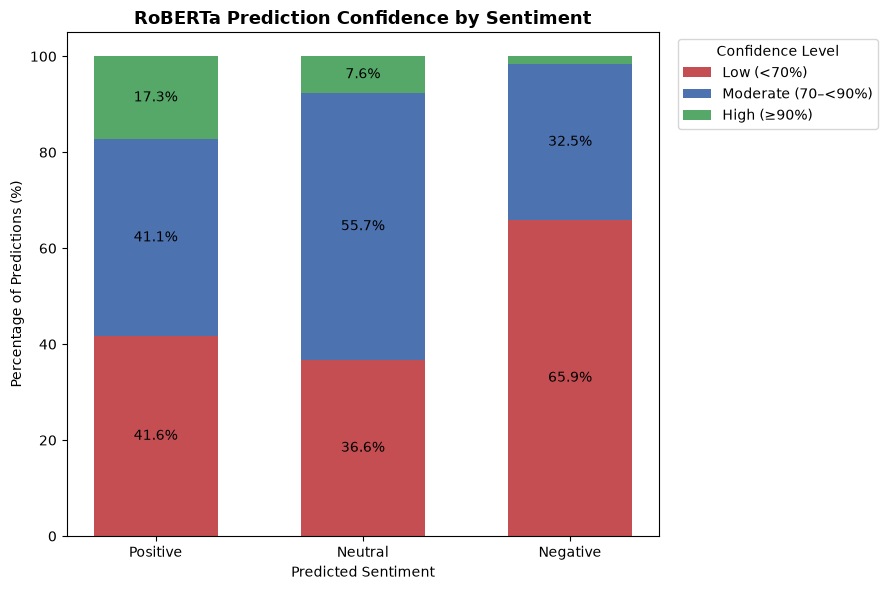

In [33]:
# Group confidence scores into categories
sentiment_df["confidence_level"] = pd.cut(
    sentiment_df["confidence_score"],
    bins=[-np.inf, 70, 90, np.inf],
    labels=["Low (<70%)", "Moderate (70–<90%)", "High (≥90%)"],
    right=False
)

CONFIDENCE_ORDER = [
    "Low (<70%)",
    "Moderate (70–<90%)",
    "High (≥90%)"
]

# Summary statistics by sentiment
confidence_summary = (
    sentiment_df.groupby("sentiment")["confidence_score"]
    .agg(
        Count="count",
        Mean="mean",
        Median="median",
        Minimum="min",
        Maximum="max"
    )
    .reindex(SENTIMENT_ORDER)
    .round(1)
)

display(confidence_summary)

# Percentage distribution of confidence levels within each sentiment
confidence_counts = pd.crosstab(
    sentiment_df["sentiment"],
    sentiment_df["confidence_level"]
).reindex(
    index=SENTIMENT_ORDER,
    columns=CONFIDENCE_ORDER,
    fill_value=0
)

confidence_pct = (
    confidence_counts
    .div(confidence_counts.sum(axis=1).replace(0, np.nan), axis=0)
    .fillna(0) * 100
)

# Stacked bar chart
fig, ax = plt.subplots(figsize=(9, 6))

confidence_colors = ["#C44E52", "#4C72B0", "#55A868"]
bottom = np.zeros(len(SENTIMENT_ORDER))

for level, color in zip(CONFIDENCE_ORDER, confidence_colors):
    values = confidence_pct[level].values

    bars = ax.bar(
        SENTIMENT_ORDER,
        values,
        bottom=bottom,
        label=level,
        color=color,
        width=0.6
    )

    for bar, value, base in zip(bars, values, bottom):
        if value >= 5:
            ax.text(
                bar.get_x() + bar.get_width() / 2,
                base + value / 2,
                f"{value:.1f}%",
                ha="center",
                va="center",
                fontsize=10
            )

    bottom += values

ax.set_title(
    "RoBERTa Prediction Confidence by Sentiment",
    fontsize=13,
    fontweight="bold"
)

ax.set_ylabel("Percentage of Predictions (%)")
ax.set_xlabel("Predicted Sentiment")
ax.set_ylim(0, 105)

ax.legend(
    title="Confidence Level",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
save_fig("roberta_confidence_levels_2", fig)
plt.show()

A considerable proportion of RoBERTa's predictions showed low-to-moderate confidence scores rather than high certainty. This uncertainty was most pronounced in the Negative sentiment category, where 65.9% of predictions had confidence scores below 70% (and only ~1.6% scored 90% or above).

### Takeaway from Sentiment Analysis
- Because the underlying survey question sought constructive recommendations and suggestions ("What one action can professors take to best support students...") rather than explicitly measuring satisfaction or attitudes, many responses did not naturally express a strong positive or negative sentiment.
- Sentiment analysis should not be treated as a mandatory default; rather, it should be applied selectively to datasets designed to capture user attitudes, opinions, or satisfaction levels, while being treated as model predictions rather than ground-truth measures.


## 6. Conclusion

- This research investigated the application of machine learning, natural language processing, and large language models to automate the analysis of open-ended survey responses. Using 1,603 valid student feedback responses from the Dryad engineering education dataset, four unsupervised topic modelling approaches—Latent Dirichlet Allocation (LDA), Non-Negative Matrix Factorization (NMF), K-Means with TF-IDF, and BERTopic—were systematically evaluated across 3, 6, and 12 topic configurations.   
- Topic Modelling Selection: While no single algorithm achieved the highest score across every evaluation metric, BERTopic was selected as the preferred modelling approach due to its strong and consistent performance across $C_v$ coherence, $U_{\text{mass}}$ coherence, and intra-topic cosine similarity. By leveraging contextual sentence embeddings (all-MiniLM-L6-v2), BERTopic effectively grouped responses by semantic meaning rather than relying solely on word frequencies, making it well suited for short, varied survey responses without requiring the number of topics to be predefined.  
- Role of Sentiment Analysis: Integrating a pretrained RoBERTa model (Twitter-RoBERTa-base-sentiment-latest) demonstrated that while sentiment classification adds valuable context to thematic findings, its utility depends heavily on the nature of the survey question. Because the analysed question sought constructive recommendations rather than subjective satisfaction ratings, 70.3% ($n = 1,127$) of responses were classified as neutral, with many predictions exhibiting low-to-moderate confidence. Consequently, sentiment analysis is best deployed as an optional analytical layer tailored to attitude- or satisfaction-oriented questions rather than as a mandatory default.   